<a href="https://colab.research.google.com/github/deboraachriss/Deepfake-Predictions/blob/main/Deepface%20Predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic ops diaktifkan.")
except Exception as e:
    print("Deterministic ops tidak tersedia, lanjut tanpa itu.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Deterministic ops diaktifkan.


In [ ]:

train_dir = "/content/drive/MyDrive/Dataset/Train"
val_dir   = "/content/drive/MyDrive/Dataset/Validation"
test_dir  = "/content/drive/MyDrive/Dataset/Test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 128

train_ds = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_ds = image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

test_ds = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Class names:", class_names)

Found 2002 files belonging to 2 classes.
Found 2002 files belonging to 2 classes.
Found 2002 files belonging to 2 classes.
Class names: ['Fake', 'Real']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

In [ ]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom(0.2),
    keras.layers.RandomContrast(0.2),
    keras.layers.RandomBrightness(0.2),
], name="data_augmentation")

In [ ]:
from tensorflow.keras import regularizers

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False  # freeze semua di awal

inputs = keras.Input(shape=(224, 224, 3), name="input_image")

# Augmentasi
x = data_augmentation(inputs)

#Preprocess sesuai MobileNetV2
x = keras.applications.mobilenet_v2.preprocess_input(x)

#Feature extractor
x = base_model(x, training=False)

#Global pooling
x = keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)

#Dense + Dropout + L2
x = keras.layers.Dropout(0.5, name="dropout_1")(x)
x = keras.layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.001),
    name="dense_128"
)(x)
x = keras.layers.Dropout(0.4, name="dropout_2")(x)

outputs = keras.layers.Dense(
    1,
    activation="sigmoid",
    kernel_regularizer=regularizers.l2(0.001),
    name="output"
)(x)

model = keras.Model(inputs, outputs, name="deepfake_mobilenetv2")

# Loss dengan label smoothing (bantu turunin val_loss)
loss_fn = keras.losses.BinaryCrossentropy(label_smoothing=0.1)


# Callback & Plot History
def get_callbacks(stage_name):
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )

    return [early_stop, reduce_lr]

def plot_history(history, title):
    acc      = history.history.get("accuracy", [])
    val_acc  = history.history.get("val_accuracy", [])
    loss     = history.history.get("loss", [])
    val_loss = history.history.get("val_loss", [])

    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14,5))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(epochs, acc, "b-o", label="Train Acc")
    plt.plot(epochs, val_acc, "r-o", label="Val Acc")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    plt.plot(epochs, loss, "b-o", label="Train Loss")
    plt.plot(epochs, val_loss, "r-o", label="Val Loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()

    plt.show()


===== INITIAL TRAINING =====
Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 1000ms/step - accuracy: 0.5395 - loss: 1.1149 - val_accuracy: 0.7378 - val_loss: 0.7958 - learning_rate: 5.0000e-04
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 917ms/step - accuracy: 0.6740 - loss: 0.8743 - val_accuracy: 0.7812 - val_loss: 0.7607 - learning_rate: 5.0000e-04
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 878ms/step - accuracy: 0.7199 - loss: 0.8097 - val_accuracy: 0.7707 - val_loss: 0.7648 - learning_rate: 5.0000e-04
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.7455 - loss: 0.7708
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 876ms/step - accuracy: 0.7453 - loss: 0.7710 - val_accuracy: 0.7303 - val_loss: 0.7784 - learning_rate: 5.0000e-04
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 873ms/step - accuracy: 0.7641 - loss: 0.7570 - val_accuracy: 0.7488 - val_loss: 0.7633 - learning_rate: 1.5000e-04
Epoch 5: early stopping
Restoring

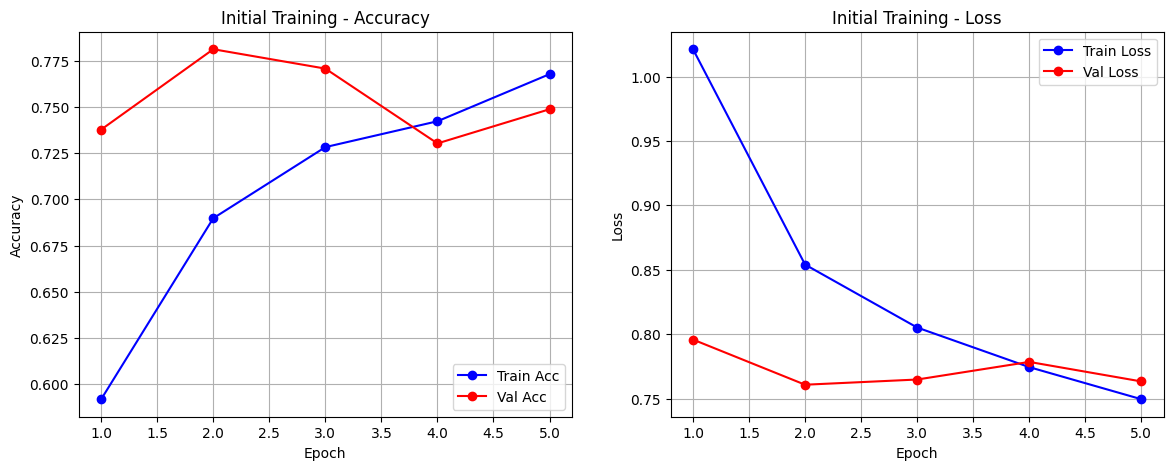

In [ ]:
INITIAL_EPOCHS = 10

model.compile(
    optimizer=keras.optimizers.Adam(5e-4),
    loss=loss_fn,
    metrics=["accuracy"]
)

print("\n===== INITIAL TRAINING =====")
history_0 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    callbacks=get_callbacks("init"),
    verbose=1
)

plot_history(history_0, "Initial Training")


===== FINE-TUNING STAGE 1 =====
Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 27s 997ms/step - accuracy: 0.6455 - loss: 0.8880 - val_accuracy: 0.7927 - val_loss: 0.7507 - learning_rate: 1.0000e-05
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 899ms/step - accuracy: 0.6646 - loss: 0.8548 - val_accuracy: 0.7957 - val_loss: 0.7407 - learning_rate: 1.0000e-05
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7066 - loss: 0.8207 - val_accuracy: 0.8007 - val_loss: 0.7307 - learning_rate: 1.0000e-05
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 901ms/step - accuracy: 0.7465 - loss: 0.7810 - val_accuracy: 0.8127 - val_loss: 0.7216 - learning_rate: 1.0000e-05
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 895ms/step - accuracy: 0.7443 - loss: 0.7738 - val_accuracy: 0.8172 - val_loss: 0.7139 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 5.


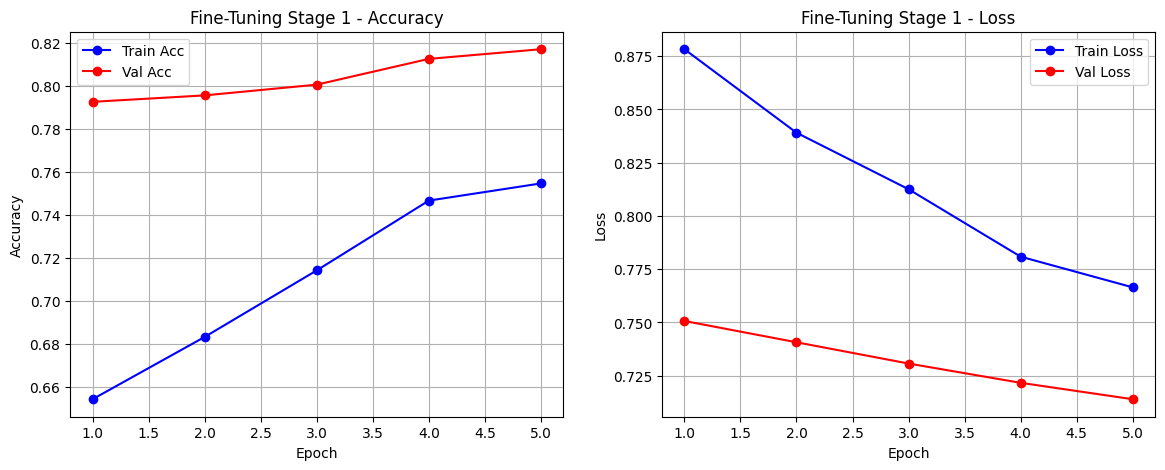

In [ ]:
print("\n===== FINE-TUNING STAGE 1 =====")
base_model.trainable = True

# Freeze sebagian besar, buka sekitar 40 layer terakhir
for layer in base_model.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss=loss_fn,
    metrics=["accuracy"]
)

FT1_EPOCHS = 5

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FT1_EPOCHS,
    callbacks=get_callbacks("ft1"),
    verbose=1
)

plot_history(history_1, "Fine-Tuning Stage 1")


===== FINE-TUNING STAGE 2 =====
Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 23s 974ms/step - accuracy: 0.7742 - loss: 0.7627 - val_accuracy: 0.8182 - val_loss: 0.7109 - learning_rate: 5.0000e-06
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 894ms/step - accuracy: 0.7763 - loss: 0.7527 - val_accuracy: 0.8197 - val_loss: 0.7077 - learning_rate: 5.0000e-06
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 884ms/step - accuracy: 0.7720 - loss: 0.7506 - val_accuracy: 0.8207 - val_loss: 0.7045 - learning_rate: 5.0000e-06
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 885ms/step - accuracy: 0.7907 - loss: 0.7394 - val_accuracy: 0.8252 - val_loss: 0.7013 - learning_rate: 5.0000e-06
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 901ms/step - accuracy: 0.7982 - loss: 0.7356 - val_accuracy: 0.8242 - val_loss: 0.6990 - learning_rate: 5.0000e-06
Restoring model weights from the end of the best epoch: 5.


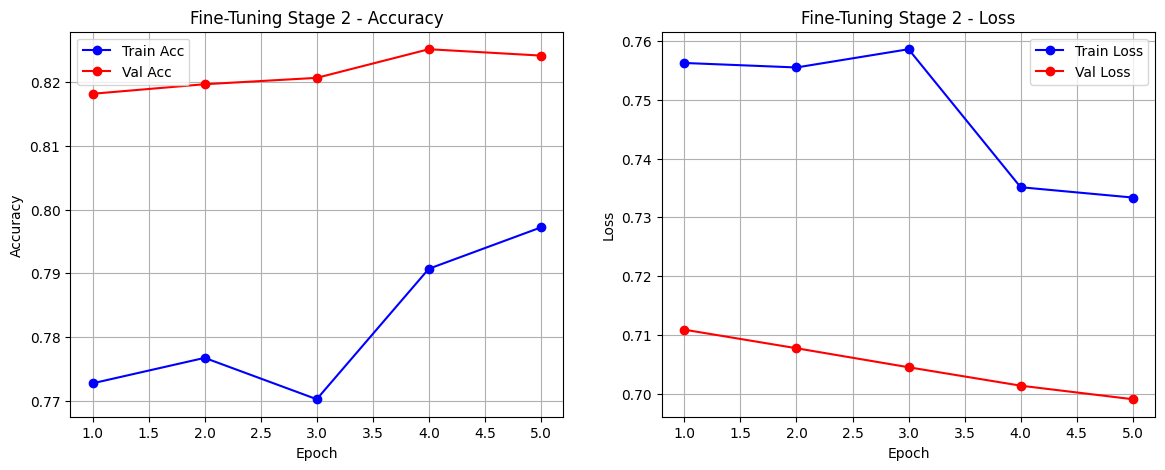

In [ ]:
print("\n===== FINE-TUNING STAGE 2 =====")
# Buka lebih banyak (misal freeze cuma 20 layer pertama)
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers[-20:]:
    layer.trainable = True

model.compile(
    optimizer=keras.optimizers.Adam(5e-6),
    loss=loss_fn,
    metrics=["accuracy"]
)

FT2_EPOCHS = 5

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FT2_EPOCHS,
    callbacks=get_callbacks("ft2"),
    verbose=1
)

plot_history(history_2, "Fine-Tuning Stage 2")


===== FINE-TUNING STAGE 3 =====
Epoch 1/3
16/16 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.7750 - loss: 0.7554 - val_accuracy: 0.8267 - val_loss: 0.6969 - learning_rate: 1.0000e-06
Epoch 2/3
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7542 - loss: 0.7626 - val_accuracy: 0.8287 - val_loss: 0.6947 - learning_rate: 1.0000e-06
Epoch 3/3
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.7674 - loss: 0.7577 - val_accuracy: 0.8272 - val_loss: 0.6929 - learning_rate: 1.0000e-06
Restoring model weights from the end of the best epoch: 3.


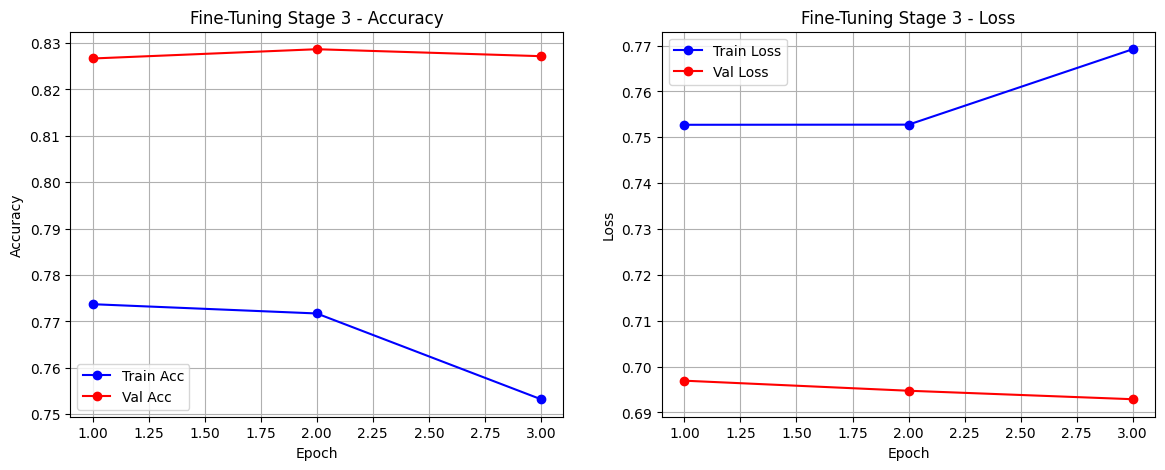

In [ ]:
print("\n===== FINE-TUNING STAGE 3 =====")
for layer in base_model.layers:
    layer.trainable = True

model.compile(
    optimizer=keras.optimizers.Adam(1e-6),
    loss=loss_fn,
    metrics=["accuracy"]
)

FT3_EPOCHS = 3

history_3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FT3_EPOCHS,
    callbacks=get_callbacks("ft3"),
    verbose=1
)

plot_history(history_3, "Fine-Tuning Stage 3")

In [ ]:
print("\n===== EVALUASI DI TEST SET =====")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print("Final Test Accuracy:", test_acc)
print("Final Test Loss:", test_loss)


===== EVALUASI DI TEST SET =====
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 430ms/step - accuracy: 0.6996 - loss: 0.8356
Final Test Accuracy: 0.789710283279419
Final Test Loss: 0.7368564009666443


In [ ]:
save_path = "/content/drive/MyDrive/deepfake_model_final_v2.keras"
model.save(save_path)
print("Model disimpan ke:", save_path)


Model disimpan ke: /content/drive/MyDrive/deepfake_model_final_v2.keras



===== UJI DENGAN GAMBAR MANUAL =====


Saving real_9.jpg to real_9.jpg
Menguji: real_9.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


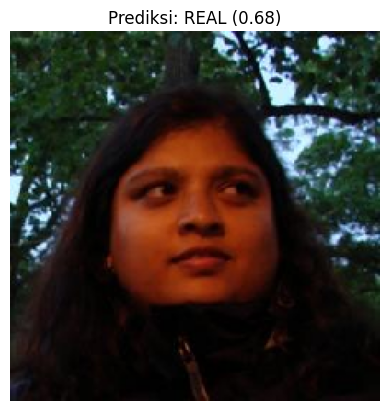

Hasil Prediksi: REAL | Confidence: 0.6800548


In [ ]:

from google.colab import files

def predict_image(img_path, threshold=0.5):
    img = keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)


    pred = model.predict(img_array)[0][0]

    if pred >= threshold:
        label = "REAL"
        confidence = pred
    else:
        label = "FAKE"
        confidence = 1 - pred

    plt.imshow(img)
    plt.title(f"Prediksi: {label} ({confidence:.2f})")
    plt.axis("off")
    plt.show()

    print("Hasil Prediksi:", label, "| Confidence:", confidence)

print("\n===== UJI DENGAN GAMBAR MANUAL =====")
uploaded = files.upload()
for fn in uploaded.keys():
    print("Menguji:", fn)
    predict_image(fn, threshold=0.5)